# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [42]:
class card:
    def __init__(self, suit, value):
        self.suit = suit
        self.value = value

    def which_card(self):
        return self.value, self.suit

    def __str__(self):
        return f"{self.value},{self.suit}"

    def __repr__(self):
        return f"{self.value}, {self.suit}"

# determines value of the cards
    def card_value(self):
        if isinstance(self.value, int):
            card_value = self.value
        else:
            if self.value in ('J', 'Q', 'K'):
                card_value = 10
            elif self.value == 'A':
                card_value = 11
        return card_value


class deck:
    def __init__(self, num_decks):
        self.num_decks = num_decks
        self.cards = self.create_deck()

    def create_deck(self):
        values = ['A',2,3,4,5,6,7,8,9,10,'J','Q','K']
        suits = ['spades', 'clubs', 'hearts', 'diamonds']
        plastic = card(None, 'plastic')
        deck = []
        for i in range(self.num_decks):
            for value in values:
                for suit in suits:
                    card_def = card(suit, value)
                    deck.append(card_def)
        deck.append(plastic)
        return deck

    def shuffle_deck(self):
        import random
        random.shuffle(self.cards)
        return self.cards

    def draw_cards(self, num_cards):
        draw = self.cards[:num_cards]
        self.cards = self.cards[num_cards:]
        for i in draw:
            if i.value == 'plastic':
                self.cards = self.create_deck()
                self.shuffle_deck()
                print('Plastic card drawn. Deck reshuffled.')
                return self.draw_cards(num_cards)
        return draw

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [43]:
class player:
    def __init__(self, name):
        self.name = name
        self.hand = hand([])

class dealer(player):
    def __init__(self, name):
        player.__init__(self, name)

class game:
    def __init__(self, players):
        self.players = players
        self.play_deck = deck(6)
        self.dealer = dealer('Dealer')
        self.play_deck.shuffle_deck()

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [67]:
#Player base class
#player has a name and chips.
class player:
    def __init__(self, name, chips):
        self.name = name
        self.chips = chips
        self.hand = []

    def __str__(self):
        return f"{self.name}"

    def my_chips(self):
        return self.chips

    def my_hand(self):
        return self.hand

    def deal_hand(self, deck):
        self.hand = deck.draw_cards(2)
        return self.hand

    def bet(self, amount=None):
        if amount == None:
            bet = int(input("How much do you want to bet?"))
            if bet <= self.chips:
                self.chips -= bet
            else:
                bet = int(input("Bet is too much, try again"))
                self.chips -= bet
        else:
            bet = amount
            self.chips -= bet
        return bet

    def take_turn(self):
        ## this will be overwritten with different player strategies ##
        raise NotImplementedError

# value of my hand. Defines if Ace is 1 or 11
    def hand_value(self):
        total_count = 0
        for card in self.hand:
            card_value = card.card_value()
            total_count += card_value
        for card in self.hand:
            if card.value == 'A':
                if total_count > 21:
                    total_count -= 10
        return total_count    

#dealer also has a name and a hand object
class dealer(player):
    def __init__(self, name, chips):
        player.__init__(self, name, chips)

    def dealer_hand(self):
        return self.hand[:1]

    def take_turn(self, deck):
        hand_value = self.hand_value()
        while hand_value <= 16:
            new_card = deck.draw_cards(1)
            self.hand.extend(new_card)
            hand_value = self.hand_value()
        return self.hand

#dumb player has a strategy
class dumb_player(player):
    def __init__(self, name, chips):
        player.__init__(self, name, chips)

    def take_turn(self, deck):
        hand_value = self.hand_value()
        while hand_value <= 21:
            new_card = deck.draw_cards(1)
            self.hand.extend(new_card)
            hand_value = self.hand_value()
        return self.hand

class dealer_strategy_player(player):
    def __init__(self, name, chips):
        player.__init__(self, name, chips)

    def take_turn(self, deck):
        hand_value = self.hand_value()
        while hand_value <= 16:
            new_card = deck.draw_cards(1)
            self.hand.extend(new_card)
            hand_value = self.hand_value()
        return self.hand
        
# players are a list of player objects
class game:
    def __init__(self, players):
        self.players = players
        self.play_deck = deck(6)
        self.dealer = dealer('Dealer', 10000)
        self.play_deck.shuffle_deck()
        self.bets = {}

    def bet_round(self, amount=None):
        for player in self.players:
            player_bet = player.bet(amount)
            self.bets[player] = player_bet
        return self.bets
            
#each player gets a hand, dealer gets a hand
    def deal_cards(self):
        for player in self.players:
            player.deal_hand(self.play_deck)
            print(f"Player Hand: {player.my_hand()}")
            
        dealer_hand = self.dealer.deal_hand(self.play_deck)
        print(self.dealer.dealer_hand())

    def taking_turns(self, threshold):
        visible_cards = []
        for player in self.players:
            visible_cards.extend(player.hand)
        visible_cards.extend(self.dealer.dealer_hand())
        for player in self.players:
            if isinstance(player, counting_player):
                player.take_turn(self.play_deck, visible_cards, threshold)
            elif isinstance(player, cautious_player):
                player.take_turn(self.play_deck, self.dealer.hand[0])
            else:
                player.take_turn(self.play_deck)
        self.dealer.take_turn(self.play_deck)
        dealer_hand_value = self.dealer.hand_value()

        winners = []
        draw = []
        if dealer_hand_value > 21:
            print("Dealer Loses")
            for player in self.players:
                player_hand_value = player.hand_value()
                if player_hand_value <= 21:
                    print(f"{player.name} wins!")
                    winners.append(player)
                else:
                    print(f"{player.name} loses")
        elif dealer_hand_value <= 21:
            if dealer_hand_value == 21:
                for player in self.players:
                    player_hand_value = player.hand_value()
                    if player_hand_value != dealer_hand_value:
                        print(f"Dealer Wins against {player.name}")
                    else:
                        print(f"{player.name} draws")
                        draw.append(player)
            else:
                for player in self.players:
                    player_hand_value = player.hand_value()
                    if player_hand_value > dealer_hand_value and player_hand_value <=21:
                        print(f"{player.name} wins!")
                        winners.append(player)
                    elif player_hand_value == dealer_hand_value:
                        print(f"{player.name} draws")
                        draw.append(player)
                    else:
                        print(f"Dealer wins against {player.name}")
        for winner in winners:
            winnings = self.bets[winner] * 2
            winner.chips += winnings
        for player in draw:
            payout = self.bets[player]
            player.chips += payout
        

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [8]:
jim = dumb_player("Jim", 100)
joe = dealer_strategy_player("Joe", 100)
players = [jim, joe]
my_game = game(players)
my_game.bet_round()
my_game.deal_cards()
my_game.taking_turns()

How much do you want to bet? 5
How much do you want to bet? 5


Player Hand: [A, diamonds, Q, clubs]
Player Hand: [6, spades, 7, clubs]
[K, spades]
Dealer Loses
Jim loses
Joe wins!


In [9]:
print(jim.my_chips())
print(joe.my_chips())

95
105


6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [56]:
class counting_player(player):
    def __init__(self, name, chips):
        player.__init__(self, name, chips)

    def take_turn(self, deck, visible_cards, threshold):
        while True:
            hand_score = 0
            for card in visible_cards:
                if 2 <= card.card_value() <= 6:
                    card_point = 1
                    hand_score += card_point
                elif 7 <= card.card_value() <= 9:
                    card_point = 0
                    hand_score += card_point
                else:
                    card_point = -1
                    hand_score += card_point
            if hand_score >= threshold:
                break
            new_card = deck.draw_cards(1)
            self.hand.extend(new_card)
            visible_cards.extend(new_card)
            if self.hand_value() > 21:
                break
        return self.hand

            

In [16]:
jim = dumb_player("Jim", 100)
joe = dealer_strategy_player("Joe", 100)
arthur = counting_player("Arthur", 100)
players = [jim, joe, arthur]
my_game = game(players)
my_game.bet_round()
my_game.deal_cards()
my_game.taking_turns()

How much do you want to bet? 10
How much do you want to bet? 10
How much do you want to bet? 10


Player Hand: [K, hearts, J, clubs]
Player Hand: [3, spades, 8, spades]
Player Hand: [6, clubs, K, spades]
[8, diamonds]
Dealer wins against Jim
Dealer wins against Joe
Dealer wins against Arthur


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [58]:
import contextlib
import io
emily = counting_player("Emily", 1000)
nick = dealer_strategy_player("Nick", 1000)
johnny = dealer_strategy_player("Johnny", 1000)
colt = dealer_strategy_player("Colt", 1000)
players = [emily, nick, johnny, colt]
my_game = game(players)
def lets_play(my_game, threshold):
    with contextlib.redirect_stdout(io.StringIO()):
        for i in range(50):
            if my_game.players[0].chips <=0:
                break
            my_game.bet_round(10)
            my_game.deal_cards()
            my_game.taking_turns(threshold)
        return my_game.players[0].chips
    

lets_play(my_game, -2)

850

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Average winnings per round: 844.5; Standard Deviation: 66.62394464454952


(array([ 6.,  9.,  8., 22., 15., 14., 20.,  3.,  1.,  2.]),
 array([ 700.,  733.,  766.,  799.,  832.,  865.,  898.,  931.,  964.,
         997., 1030.]),
 <BarContainer object of 10 artists>)

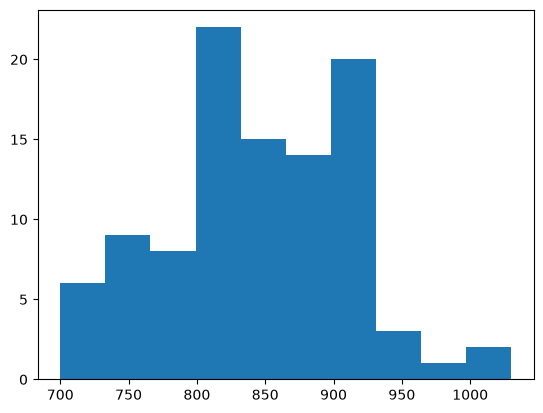

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import contextlib
import io
def game_sim(threshold):
    winnings = []
    for i in range(100):
        james = counting_player("James", 1000)
        john = dealer_strategy_player("John", 1000)
        bill = dealer_strategy_player("Bill", 1000)
        randy = dealer_strategy_player("Randy", 1000)
        players = [james, john, bill, randy]
        game_iteration = game(players)
        end_amount = lets_play(game_iteration, threshold)
        winnings.append(end_amount)
    return winnings
final_counts = game_sim(-2)
mean = np.mean(final_counts)
sd = np.std(final_counts)
print(f"Average winnings per round: {mean}; Standard Deviation: {sd}")
plt.hist(final_counts)


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

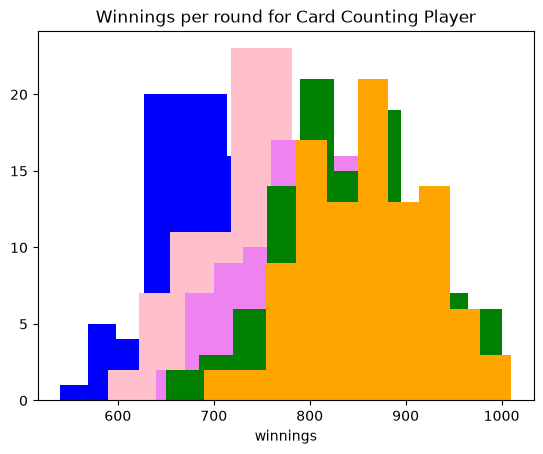

In [66]:
game_sim1 = game_sim(1)
game_sim2 = game_sim(0)
game_sim3 = game_sim(-1)
game_sim4 = game_sim(-2)
game_sim5 = game_sim(-3)
plt.hist(game_sim1, color="blue")
plt.hist(game_sim2, color="pink")
plt.hist(game_sim3, color="violet")
plt.hist(game_sim4, color="green")
plt.hist(game_sim5, color="orange")
plt.xlabel("winnings")
plt.title("Winnings per round for Card Counting Player")
plt.show()

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [72]:
class cautious_player(player):
    def __init__(self, name, chips):
        player.__init__(self, name, chips)

    def take_turn(self, deck, dealer_card):
        if 2 <= dealer_card.card_value() <= 6:
            stand_value = 12
        else:
            stand_value = 17

        while self.hand_value() < stand_value:
            new_card = deck.draw_cards(1)
            self.hand.extend(new_card)

        return self.hand

In [75]:
def game_sim(threshold):
    winnings = []
    for i in range(100):
        james = cautious_player("James", 1000)
        john = dealer_strategy_player("John", 1000)
        bill = dealer_strategy_player("Bill", 1000)
        randy = dealer_strategy_player("Randy", 1000)
        players = [james, john, bill, randy]
        game_iteration = game(players)
        end_amount = lets_play(game_iteration, threshold)
        winnings.append(end_amount)
    return winnings

Average winnings per round: 971.4; Standard Deviation: 64.29650068238551


(array([ 3.,  0.,  3.,  7., 20., 21., 21., 12.,  9.,  4.]),
 array([ 730.,  773.,  816.,  859.,  902.,  945.,  988., 1031., 1074.,
        1117., 1160.]),
 <BarContainer object of 10 artists>)

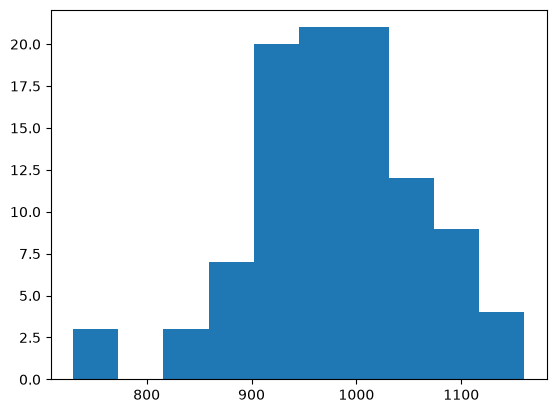

In [78]:
cautious_strategy = game_sim(-2)
mean = np.mean(final_counts)
sd = np.std(final_counts)
print(f"Average winnings per round: {mean}; Standard Deviation: {sd}")
plt.hist(cautious_strategy)

In [79]:
def game_sim_cautious(threshold):
    winnings = []
    for i in range(100):
        james = cautious_player("James", 1000)
        john = dealer_strategy_player("John", 1000)
        bill = dealer_strategy_player("Bill", 1000)
        randy = dealer_strategy_player("Randy", 1000)
        players = [james, john, bill, randy]
        game_iteration = game(players)
        end_amount = lets_play(game_iteration, threshold)
        winnings.append(end_amount)
    return winnings

def game_sim_counting(threshold):
    winnings = []
    for i in range(100):
        james = counting_player("Michael", 1000)
        john = dealer_strategy_player("John", 1000)
        bill = dealer_strategy_player("Bill", 1000)
        randy = dealer_strategy_player("Randy", 1000)
        players = [james, john, bill, randy]
        game_iteration = game(players)
        end_amount = lets_play(game_iteration, threshold)
        winnings.append(end_amount)
    return winnings

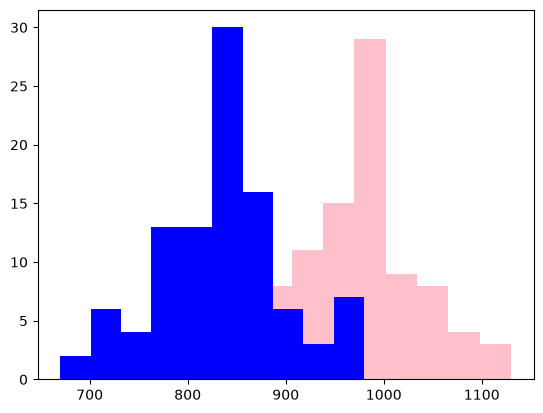

In [81]:
cautious = game_sim_cautious(-2)
counting = game_sim_counting(-2)

plt.hist(cautious, color = "pink")
plt.hist(counting, color = "blue")
plt.show()

CAUTIOUS PLAYER WINS MORE THAN THE COUNTING PLAYER!!!